# 04 - Modelo Mixto de Interacción: Scheirer-Ray-Hare

## Objetivo
- Evaluar si existe interacción entre sistema de recuperación y modelo en las métricas
- El test de Scheirer-Ray-Hare (SRH) es la alternativa no paramétrica al ANOVA de dos factores
- Se basa en aplicar ANOVA de dos factores sobre los rangos de los datos

## Diseño factorial
- Factor A: sistema de recuperación (3 niveles)
- Factor B: modelo (3 niveles)
- VR: métricas seleccionadas

In [1]:
import json
import polars as pl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from pathlib import Path

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 8)})

DATA_DIR = Path("..") / "part_i"

In [2]:
df = pl.read_csv(DATA_DIR / "combined_metrics_for_analysis.csv")
print(f"Datos: {df.shape}")

# Cargar VR seleccionadas desde el archivo compartido
with open("vr_seleccionadas.json", "r", encoding="utf-8") as f:
    vr_config = json.load(f)

VR_SELECCIONADAS = vr_config["vr_seleccionadas"]

ESTRATEGIAS = sorted(df["estrategia"].unique().to_list())
MODELOS = sorted(df["id_modelo_especialista"].unique().to_list())

print(f"\nVR seleccionadas ({len(VR_SELECCIONADAS)}): {VR_SELECCIONADAS}")

# Verificar diseño factorial
conteo = df.group_by(["estrategia", "id_modelo_especialista"]).len()
print("\nConteo por celda del diseño:")
display(conteo.sort("estrategia", "id_modelo_especialista"))

Datos: (711, 22)

VR seleccionadas (1): ['respuesta_correcta_avg']

Conteo por celda del diseño:


estrategia,id_modelo_especialista,len
str,str,u32
"""llm_responses_agentic_rag""","""gpt-5""",79
"""llm_responses_agentic_rag""","""gpt-5-mini""",79
"""llm_responses_agentic_rag""","""gpt-5-nano""",79
"""llm_responses_base_rag""","""gpt-5""",79
"""llm_responses_base_rag""","""gpt-5-mini""",79
"""llm_responses_base_rag""","""gpt-5-nano""",79
"""llm_responses_no_rag""","""gpt-5""",79
"""llm_responses_no_rag""","""gpt-5-mini""",79
"""llm_responses_no_rag""","""gpt-5-nano""",79


## 1. Test de Scheirer-Ray-Hare

Implementación manual:
1. Asignar rangos a todos los datos combinados
2. Aplicar ANOVA de dos factores sobre los rangos
3. Cada efecto (A, B, A×B) se evalúa con H = SS_efecto / MS_total_rangos
4. H sigue una distribución chi-cuadrado

In [3]:
def scheirer_ray_hare(df_pl, factor_a_col, factor_b_col, value_col):
    """Scheirer-Ray-Hare test (non-parametric two-way ANOVA on ranks)."""
    pdf = df_pl.select([factor_a_col, factor_b_col, value_col]).drop_nulls().to_pandas()
    N = len(pdf)

    # Asignar rangos globales
    pdf["rank"] = stats.rankdata(pdf[value_col])

    # Medias de rangos
    grand_mean = pdf["rank"].mean()

    # Niveles
    a_levels = sorted(pdf[factor_a_col].unique())
    b_levels = sorted(pdf[factor_b_col].unique())
    a_k = len(a_levels)
    b_k = len(b_levels)

    # SS total de rangos
    SS_total = np.sum((pdf["rank"] - grand_mean) ** 2)

    # SS Factor A
    SS_A = 0
    for a in a_levels:
        n_a = len(pdf[pdf[factor_a_col] == a])
        mean_a = pdf[pdf[factor_a_col] == a]["rank"].mean()
        SS_A += n_a * (mean_a - grand_mean) ** 2

    # SS Factor B
    SS_B = 0
    for b in b_levels:
        n_b = len(pdf[pdf[factor_b_col] == b])
        mean_b = pdf[pdf[factor_b_col] == b]["rank"].mean()
        SS_B += n_b * (mean_b - grand_mean) ** 2

    # SS Interacción (AB)
    SS_cells = 0
    for a in a_levels:
        for b in b_levels:
            mask = (pdf[factor_a_col] == a) & (pdf[factor_b_col] == b)
            n_ab = mask.sum()
            if n_ab > 0:
                mean_ab = pdf[mask]["rank"].mean()
                SS_cells += n_ab * (mean_ab - grand_mean) ** 2
    SS_AB = SS_cells - SS_A - SS_B

    # MS total
    MS_total = SS_total / (N - 1)

    # Estadísticos H
    df_A = a_k - 1
    df_B = b_k - 1
    df_AB = df_A * df_B

    H_A = SS_A / MS_total
    H_B = SS_B / MS_total
    H_AB = SS_AB / MS_total

    p_A = 1 - stats.chi2.cdf(H_A, df_A)
    p_B = 1 - stats.chi2.cdf(H_B, df_B)
    p_AB = 1 - stats.chi2.cdf(H_AB, df_AB)

    return {
        "factor_A": {"SS": SS_A, "df": df_A, "H": H_A, "p": p_A},
        "factor_B": {"SS": SS_B, "df": df_B, "H": H_B, "p": p_B},
        "interaction_AB": {"SS": SS_AB, "df": df_AB, "H": H_AB, "p": p_AB},
        "total": {"SS": SS_total, "df": N - 1, "MS": MS_total},
    }

print("Función scheirer_ray_hare definida.")

Función scheirer_ray_hare definida.


In [4]:
srh_results = []

print(f"{'Métrica':<30} {'Efecto':<15} {'H':>10} {'df':>5} {'p-valor':>12} {'Sig.':>5}")
print("=" * 80)

for metrica in VR_SELECCIONADAS:
    result = scheirer_ray_hare(df, "estrategia", "id_modelo_especialista", metrica)

    for effect_name, effect_label in [
        ("factor_A", "Sistema"),
        ("factor_B", "Modelo"),
        ("interaction_AB", "Interacción"),
    ]:
        r = result[effect_name]
        sig = "*" if r["p"] < 0.05 else ""
        sig += "*" if r["p"] < 0.01 else ""
        sig += "*" if r["p"] < 0.001 else ""
        print(f"{metrica:<30} {effect_label:<15} {r['H']:>10.4f} {r['df']:>5} {r['p']:>12.6f} {sig:>5}")

        srh_results.append({
            "metrica": metrica,
            "efecto": effect_label,
            "H_statistic": round(r["H"], 4),
            "df": r["df"],
            "p_value": r["p"],
            "significativo": r["p"] < 0.05,
        })
    print("-" * 80)

df_srh = pl.DataFrame(srh_results)

Métrica                        Efecto                   H    df      p-valor  Sig.
respuesta_correcta_avg         Sistema            21.8257     2     0.000018   ***
respuesta_correcta_avg         Modelo             49.0121     2     0.000000   ***
respuesta_correcta_avg         Interacción        56.6227     4     0.000000   ***
--------------------------------------------------------------------------------


## 2. Tabla resumen de efectos significativos

In [5]:
# Tabla pivotada: efecto × métrica con p-values
for efecto in ["Sistema", "Modelo", "Interacción"]:
    subset = df_srh.filter(pl.col("efecto") == efecto)
    print(f"\n--- Efecto: {efecto} ---")
    for row in subset.iter_rows(named=True):
        sig = "✓" if row["significativo"] else "✗"
        print(f"  {row['metrica']:<35} H={row['H_statistic']:<10.4f} p={row['p_value']:.6f}  {sig}")



--- Efecto: Sistema ---
  respuesta_correcta_avg              H=21.8257    p=0.000018  ✓

--- Efecto: Modelo ---
  respuesta_correcta_avg              H=49.0121    p=0.000000  ✓

--- Efecto: Interacción ---
  respuesta_correcta_avg              H=56.6227    p=0.000000  ✓


## 3. Gráficos de interacción

Si hay interacción significativa, la superioridad de un modelo puede depender del sistema.

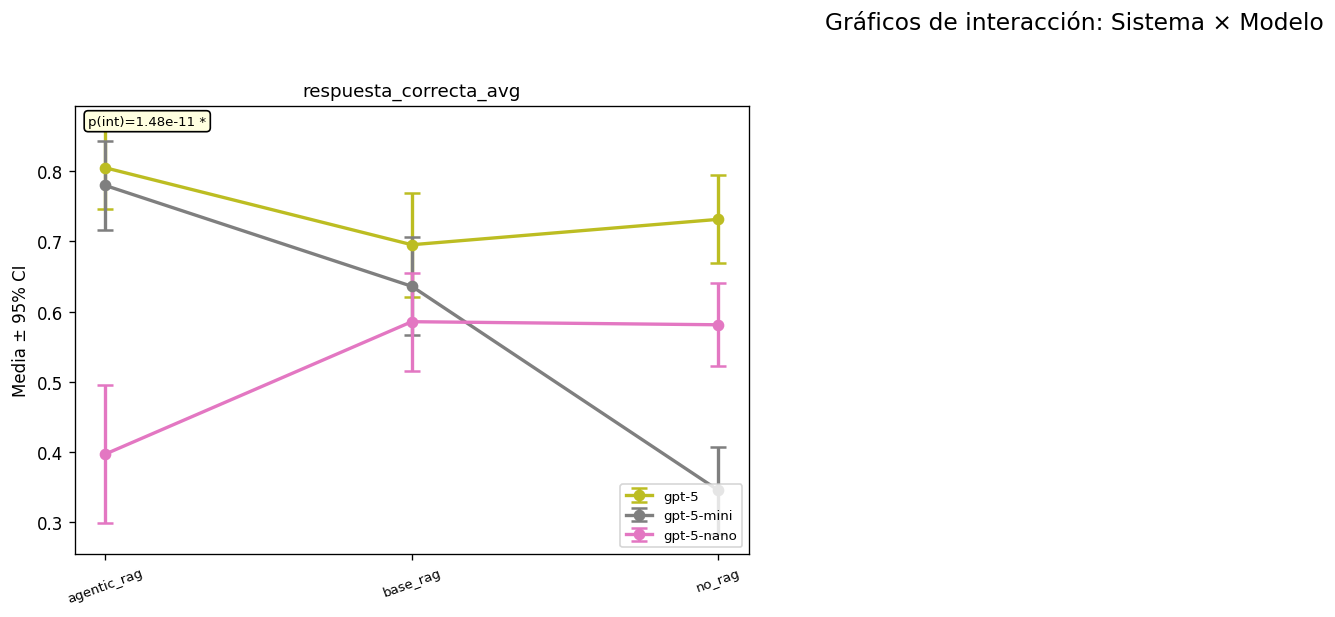

In [6]:
est_labels = {e: e.replace("llm_responses_", "") for e in ESTRATEGIAS}
colores_modelo = {"gpt-5-nano": "#e377c2", "gpt-5-mini": "#7f7f7f", "gpt-5": "#bcbd22"}

n_metrics = len(VR_SELECCIONADAS)
n_cols = 3
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

for i, metrica in enumerate(VR_SELECCIONADAS):
    ax = axes[i]

    for modelo in MODELOS:
        means = []
        cis = []
        for est in ESTRATEGIAS:
            vals = df.filter(
                (pl.col("estrategia") == est) &
                (pl.col("id_modelo_especialista") == modelo)
            )[metrica].drop_nulls().to_numpy()
            means.append(vals.mean())
            se = vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0
            cis.append(1.96 * se)

        x_pos = np.arange(len(ESTRATEGIAS))
        ax.errorbar(
            x_pos, means, yerr=cis,
            marker="o", capsize=5, capthick=1.5, linewidth=2,
            color=colores_modelo[modelo], label=modelo,
        )

    ax.set_xticks(range(len(ESTRATEGIAS)))
    ax.set_xticklabels([est_labels[e] for e in ESTRATEGIAS], rotation=20, fontsize=8)
    ax.set_title(metrica, fontsize=11)
    ax.set_ylabel("Media ± 95% CI")

    # Agregar p-value de interacción
    p_int = df_srh.filter(
        (pl.col("metrica") == metrica) & (pl.col("efecto") == "Interacción")
    )["p_value"][0]
    sig_text = f"p(int)={p_int:.4f}" if p_int >= 0.0001 else f"p(int)={p_int:.2e}"
    if p_int < 0.05:
        sig_text += " *"
    ax.text(0.02, 0.98, sig_text, transform=ax.transAxes, fontsize=8,
            va="top", ha="left", bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow"))

    if i == 0:
        ax.legend(fontsize=8, loc="lower right")

for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Gráficos de interacción: Sistema × Modelo", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 4. Medias por combinación sistema × modelo

In [7]:
print("\nMedias por combinación Sistema × Modelo:")
print(f"{'Estrategia':<20} {'Modelo':<15} ", end="")
for m in VR_SELECCIONADAS:
    print(f"{m[:12]:>14}", end="")
print()
print("=" * (35 + 14 * len(VR_SELECCIONADAS)))

for est in ESTRATEGIAS:
    for modelo in MODELOS:
        subset = df.filter(
            (pl.col("estrategia") == est) &
            (pl.col("id_modelo_especialista") == modelo)
        )
        est_short = est.replace("llm_responses_", "")
        print(f"{est_short:<20} {modelo:<15} ", end="")
        for metrica in VR_SELECCIONADAS:
            val = subset[metrica].mean()
            if val is not None:
                print(f"{val:>14.4f}", end="")
            else:
                print(f"{'N/A':>14}", end="")
        print()


Medias por combinación Sistema × Modelo:
Estrategia           Modelo            respuesta_co
agentic_rag          gpt-5                   0.8048
agentic_rag          gpt-5-mini              0.7796
agentic_rag          gpt-5-nano              0.3969
base_rag             gpt-5                   0.6952
base_rag             gpt-5-mini              0.6360
base_rag             gpt-5-nano              0.5855
no_rag               gpt-5                   0.7314
no_rag               gpt-5-mini              0.3454
no_rag               gpt-5-nano              0.5811


## 5. Resumen final

In [8]:
print("="*60)
print("RESUMEN SCHEIRER-RAY-HARE")
print("="*60)

for efecto in ["Sistema", "Modelo", "Interacción"]:
    subset = df_srh.filter(
        (pl.col("efecto") == efecto) & (pl.col("significativo") == True)
    )
    n_sig = len(subset)
    print(f"\n{efecto}: {n_sig}/{len(VR_SELECCIONADAS)} métricas con efecto significativo")
    if n_sig > 0:
        for row in subset.iter_rows(named=True):
            print(f"  → {row['metrica']}: H={row['H_statistic']:.4f}, p={row['p_value']:.6f}")

print("\n--- Interpretación ---")
print("Si la interacción es significativa, el efecto de un factor depende del otro.")
print("En ese caso, las comparaciones marginales (solo sistema o solo modelo) son insuficientes.")
print("Se recomienda analizar efectos simples (comparar modelos dentro de cada sistema).")


RESUMEN SCHEIRER-RAY-HARE

Sistema: 1/1 métricas con efecto significativo
  → respuesta_correcta_avg: H=21.8257, p=0.000018

Modelo: 1/1 métricas con efecto significativo
  → respuesta_correcta_avg: H=49.0121, p=0.000000

Interacción: 1/1 métricas con efecto significativo
  → respuesta_correcta_avg: H=56.6227, p=0.000000

--- Interpretación ---
Si la interacción es significativa, el efecto de un factor depende del otro.
En ese caso, las comparaciones marginales (solo sistema o solo modelo) son insuficientes.
Se recomienda analizar efectos simples (comparar modelos dentro de cada sistema).



## 6. Conclusión Final

### 6.1 Resultados del test de Scheirer-Ray-Hare

El test de Scheirer-Ray-Hare (alternativa no paramétrica al ANOVA de dos factores) reveló efectos **altamente significativos** para los tres componentes evaluados sobre la métrica `respuesta_correcta_avg`:

| Efecto | H | gl | p-valor | Significativo |
|---|---|---|---|---|
| Sistema de recuperación | 21.83 | 2 | 0.000018 | **Sí** |
| Modelo | 49.01 | 2 | < 0.0001 | **Sí** |
| **Interacción Sistema × Modelo** | **56.62** | **4** | **1.48 × 10⁻¹¹** | **Sí** |

El hallazgo más relevante es la **interacción significativa** (p = 1.48 × 10⁻¹¹), cuyo estadístico H (56.62) supera incluso al de los efectos principales. Esto indica que **la superioridad de un modelo depende del sistema de recuperación utilizado, y viceversa**. En consecuencia, los efectos marginales reportados en el notebook anterior (Kruskal-Wallis univariado) deben interpretarse con cautela, ya que los promedios marginales pueden enmascarar patrones de interacción complejos.

### 6.2 Patrón de interacción observado

El gráfico de interacción revela un patrón de **líneas cruzadas** (interacción disordinal), lo que implica que no existe una estrategia o modelo universalmente superior. Se observan los siguientes comportamientos diferenciados:

| Modelo | agentic_rag | base_rag | no_rag | Patrón |
|---|---|---|---|---|
| gpt-5 | **0.80** | 0.70 | 0.73 | Rendimiento alto y estable; se beneficia moderadamente del RAG |
| gpt-5-mini | 0.78 | 0.64 | **0.35** | Alta dependencia del sistema de recuperación; colapsa sin RAG |
| gpt-5-nano | 0.40 | 0.59 | 0.58 | Comportamiento contraintuitivo: peor rendimiento con agentic_rag |

**Observaciones clave**:

1. **gpt-5** mantiene un rendimiento robusto independientemente del sistema (~0.70–0.80). El agentic_rag le aporta una mejora marginal, pero incluso sin RAG obtiene resultados competitivos (0.73). Esto sugiere que su mayor capacidad de razonamiento interno compensa parcialmente la ausencia de contexto recuperado.

2. **gpt-5-mini** es el modelo más sensible al sistema de recuperación. Con agentic_rag alcanza niveles comparables a gpt-5 (0.78), pero sin RAG cae drásticamente a 0.35. Esto indica que este modelo depende fuertemente del contexto externo para generar respuestas correctas.

3. **gpt-5-nano** presenta un comportamiento inesperado: su rendimiento con agentic_rag (0.40) es **inferior** al obtenido con base_rag (0.59) o sin RAG (0.58). Esto sugiere que el sistema agéntico, al ser más complejo, podría generar contextos o instrucciones que el modelo más pequeño no logra procesar adecuadamente, degradando su rendimiento.

### 6.3 Implicaciones para el análisis marginal previo

La presencia de interacción significativa tiene consecuencias directas para la interpretación del análisis de Kruskal-Wallis (notebook 03):

- La conclusión de que "agentic_rag y base_rag no difieren significativamente" es un promedio marginal que **oculta** el hecho de que la diferencia depende del modelo. Para gpt-5-mini, la diferencia es sustancial (0.78 vs. 0.64); para gpt-5-nano, la relación se invierte (0.40 vs. 0.59).
- El hallazgo de que "base_rag ecualiza los modelos" se confirma parcialmente (rango 0.59–0.70 en base_rag), pero se matiza: esta igualación no ocurre con agentic_rag, donde las diferencias entre modelos se amplifican.

### 6.4 Implicaciones prácticas

1. **Combinación óptima**: La combinación **agentic_rag + gpt-5** (media = 0.80) produce los mejores resultados, seguida de **agentic_rag + gpt-5-mini** (0.78). Si se dispone de un modelo de alta capacidad, el sistema agéntico maximiza su rendimiento.

2. **Estrategia costo-eficiente**: Si se busca reducir costos usando gpt-5-mini, es **imprescindible** acompañarlo de un sistema de recuperación (idealmente agentic_rag). Sin RAG, su rendimiento es inaceptable (0.35).

3. **Precaución con modelos pequeños y sistemas complejos**: La combinación agentic_rag + gpt-5-nano produce el peor resultado del conjunto (0.40). En aplicaciones con modelos de capacidad limitada, un sistema de recuperación más simple (base_rag) puede ser preferible.

4. **No existe una recomendación universal**: La elección del sistema de recuperación debe considerar el modelo disponible, y viceversa. La interacción significativa invalida cualquier recomendación que trate ambos factores como independientes.

### 6.5 Observaciones metodológicas

1. **Validación cruzada de resultados**: Los estadísticos H para sistema (21.83) y modelo (49.01) coinciden exactamente con los valores obtenidos mediante Kruskal-Wallis en el notebook anterior, lo cual es esperable ya que el test SRH opera sobre los rangos de la misma forma para los efectos principales. La contribución única de este análisis es el componente de interacción.

2. **Magnitud del efecto de interacción**: Que el H de la interacción (56.62) sea mayor que ambos efectos principales indica que las combinaciones específicas sistema×modelo explican más variabilidad en los rangos que cualquiera de los factores por sí solo.

3. **Limitación de la métrica única**: Al igual que en el análisis anterior, estos resultados se basan en `respuesta_correcta_avg` como única variable respuesta. Es recomendable complementar con métricas de otras dimensiones (completitud, coherencia, fidelidad) para determinar si el patrón de interacción se replica o si es específico de esta métrica.

4. **Tamaño del diseño**: Con 79 observaciones por celda (9 celdas, N=711), el diseño factorial está razonablemente balanceado, lo cual favorece la robustez del test SRH.

